# 17. Evaluación de los modelos de clasificación

Tarea: predecir si en una celda habrá **al menos un sismo M ≥ 2,5 el mes siguiente** (cap. 13.1). Este
capítulo responde a la sección 5.1 del enunciado con la **evaluación definitiva en origen móvil** (cap. 13.11):
cada año de 2021 a 2026 los modelos se reentrenan con todo el pasado y pronostican los meses de ese año
(69 meses, 11 754 filas celda × mes). Se reportan métricas, matrices de confusión y curvas ROC, la comparación
de las técnicas de balanceo y la calibración de probabilidades.

**Combinaciones evaluadas.** Las 26 de la sección 13.12: los 7 modelos × 4 técnicas de balanceo con
optimización bayesiana (TPE), sin los dos pares equivalentes. Las 112 combinaciones con los cuatro
optimizadores están en la validación anidada (cap. 14).

**Regla de selección.** Cuando hay que elegir «la mejor combinación de cada modelo» (su campeón), se usa el
AUC de la validación interna con datos **anteriores a 2016**, la misma que fijó sus hiperparámetros. Los meses
evaluados nunca intervienen en una elección.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Predicciones de clasificación en el origen móvil 2021–2026 y campeones por modelo
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score, brier_score_loss)
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from src import benchmark as bm, resultados_e2 as r2, estadistica as est
C = r2.origen_movil_clf()
F = r2.filas_origen_movil()
yb, tmo = C["y"], C["tm"]
anio = 2004 + tmo // 12
CAMP = r2.campeones_om("clf")
print(f"{len(C['combos'])} combinaciones; origen móvil 2021–2026: {len(yb)} filas, {len(np.unique(tmo))} meses, prevalencia {yb.mean():.3f}")

26 combinaciones; origen móvil 2021–2026: 11754 filas, 69 meses, prevalencia 0.203


## 17.1 Métrica principal de validación y por qué

- **ROC-AUC es la métrica de selección** (validación interna y externa). El uso previsto es **priorizar
  celdas** por riesgo de actividad el mes siguiente: importa el **orden** de las celdas, no un umbral fijo.
  Además, con una prevalencia de ≈ 22 %, el accuracy premia al clasificador trivial que siempre dice «no habrá
  sismo» (≈ 78 % de acierto sin aprender nada).
- **Recall (sensibilidad) es la métrica secundaria clave.** Un **falso negativo** (no anticipar actividad en
  una celda que sí la tuvo) es el error más costoso para un uso de alerta y preparación; un falso positivo
  solo cuesta atención adicional sobre una celda.
- **Average Precision (AP)** resume precisión–recall y es más sensible que el AUC a la clase minoritaria;
  **Brier** y **ECE** miden la calibración (17.5).

## 17.2 Métricas de las 26 combinaciones

Las métricas que dependen de un umbral se calculan con dos reglas, ambas fijadas sin mirar los meses
evaluados:

- **Umbral 0,5** sobre la probabilidad (SVM: 0 sobre la función de decisión). Muestra el efecto directo del
  balanceo.
- **Umbral por prevalencia.** Cada mes se marcan como «habrá sismo» las celdas con mayor puntaje, en la misma
  proporción en que hubo sismo en el entrenamiento de su origen (≈ 21–24 %). Es una regla operativa: el
  pronóstico de un mes se hace para todas las celdas a la vez, y la proporción viene del pasado. Funciona
  igual con probabilidades bien o mal calibradas y con la función de decisión de la SVM.

In [3]:
# Umbral por prevalencia: en cada mes se marcan como positivas tantas celdas como la prevalencia esperada
def es_prob(etq):
    return not etq.startswith("SVM")

def pred_prevalencia(s):
    out = np.zeros(len(s), int)
    for m in np.unique(tmo):
        i = np.where(tmo == m)[0]
        k = int(round(F["prevalencia_entrenamiento"][i[0]] * len(i)))
        out[i[np.argsort(-s[i])[:k]]] = 1
    return out

filas = []
for etq, s in C["combos"].items():
    mod, bal = etq.split(" · ")
    m05 = bm.metricas_clf(yb, s, es_prob=es_prob(etq))
    pp = pred_prevalencia(s)
    filas.append({"modelo": mod, "balanceo": bal, "AUC validación < 2016": C["AUC_CV"][etq], "ROC_AUC": m05["ROC_AUC"], "AP": m05["AP"],
                  "Brier": m05["Brier"], "Recall (0,5)": m05["Recall"], "F1 (0,5)": m05["F1"], "Accuracy (0,5)": m05["Accuracy"],
                  "Recall (prev.)": recall_score(yb, pp), "Precision (prev.)": precision_score(yb, pp), "F1 (prev.)": f1_score(yb, pp)})
TP = pd.DataFrame(filas)
eda.guardar_tabla(TP, "e2_clf_prueba.csv")
TP.sort_values("ROC_AUC", ascending=False).round(3)

,modelo,balanceo,AUC validación < 2016,ROC_AUC,AP,Brier,"Recall (0,5)","F1 (0,5)","Accuracy (0,5)",Recall (prev.),Precision (prev.),F1 (prev.)
21,XGBoost,c_weight,0.701,0.810,0.584,0.167,0.625,0.525,0.770,0.561,0.503,0.530
18,XGBoost,sin bal.,0.700,0.809,0.581,0.122,0.291,0.418,0.836,0.561,0.503,0.530
14,Random Forest,sin bal.,0.696,0.807,0.581,0.122,0.282,0.412,0.837,0.559,0.501,0.528
17,Random Forest,c_weight,0.696,0.804,0.578,0.169,0.614,0.521,0.771,0.553,0.496,0.523
15,Random Forest,SMOTE,0.693,0.802,0.572,0.160,0.569,0.515,0.783,0.545,0.489,0.515
9,Regresión logística (L1/L2),c_weight,0.697,0.802,0.573,0.176,0.660,0.507,0.740,0.549,0.493,0.519
7,Regresión logística (L1/L2),SMOTE,0.697,0.801,0.572,0.176,0.665,0.506,0.737,0.545,0.489,0.516
8,Regresión logística (L1/L2),ADASYN,0.696,0.801,0.569,0.191,0.715,0.497,0.706,0.545,0.489,0.515
6,Regresión logística (L1/L2),sin bal.,0.697,0.801,0.574,0.125,0.243,0.370,0.833,0.549,0.493,0.520
0,KNN,sin bal.,0.687,0.800,0.563,0.125,0.238,0.363,0.831,0.546,0.490,0.516


In [4]:
md(f"- El AUC va de {TP.ROC_AUC.min():.3f} a {TP.ROC_AUC.max():.3f}. La correlación de Spearman entre el AUC de la validación anterior "
   f"a 2016 y el AUC de 2021–2026 es {stats.spearmanr(TP['AUC validación < 2016'], TP.ROC_AUC)[0]:.2f}: la validación con datos viejos "
   f"ordena razonablemente a las combinaciones, así que elegir con ella es sensato.\n"
   f"- Con umbral 0,5, las combinaciones **sin balanceo** tienen accuracy alto pero recall bajo (mediana "
   f"{TP[TP.balanceo == 'sin bal.']['Recall (0,5)'].median():.2f}), mientras que SMOTE, ADASYN y class_weight suben el recall "
   f"(medianas {TP[TP.balanceo == 'SMOTE']['Recall (0,5)'].median():.2f}, {TP[TP.balanceo == 'ADASYN']['Recall (0,5)'].median():.2f} y "
   f"{TP[TP.balanceo == 'c_weight']['Recall (0,5)'].median():.2f}) a costa de precisión: el balanceo mueve las probabilidades hacia arriba.\n"
   f"- Con el umbral por prevalencia el recall ya no depende del balanceo (mediana {TP['Recall (prev.)'].median():.2f}): solo depende de qué "
   f"tan bien ordena cada modelo.")

- El AUC va de 0.719 a 0.810. La correlación de Spearman entre el AUC de la validación anterior a 2016 y el AUC de 2021–2026 es 0.79: la validación con datos viejos ordena razonablemente a las combinaciones, así que elegir con ella es sensato.
- Con umbral 0,5, las combinaciones **sin balanceo** tienen accuracy alto pero recall bajo (mediana 0.25), mientras que SMOTE, ADASYN y class_weight suben el recall (medianas 0.62, 0.65 y 0.62) a costa de precisión: el balanceo mueve las probabilidades hacia arriba.
- Con el umbral por prevalencia el recall ya no depende del balanceo (mediana 0.54): solo depende de qué tan bien ordena cada modelo.

### Campeón de cada modelo

Para cada modelo, la técnica de balanceo con mejor AUC en la validación anterior a 2016.

In [5]:
# Métricas de clasificación de los campeones (Accuracy, Precision, Recall, F1, AUC, AP)
filas = []
for _, c in CAMP.iterrows():
    s = C["combos"][c.etiqueta]; pp = pred_prevalencia(s)
    filas.append({"modelo": c.modelo, "balanceo": c.variante, "etiqueta": c.etiqueta, "AUC validación < 2016": c["validación < 2016"],
                  "Accuracy": accuracy_score(yb, pp), "Precision": precision_score(yb, pp), "Recall": recall_score(yb, pp),
                  "F1": f1_score(yb, pp), "AUC": roc_auc_score(yb, s), "AP": average_precision_score(yb, s)})
TB = pd.DataFrame(filas).sort_values("AUC", ascending=False)
eda.guardar_tabla(TB, "e2_clf_mejores_por_modelo.csv")
TB.drop(columns="etiqueta").round(3)

,modelo,balanceo,AUC validación < 2016,Accuracy,Precision,Recall,F1,AUC,AP
0,XGBoost,class_weight,0.701,0.799,0.503,0.561,0.530,0.810,0.584
3,Random Forest,sin balanceo,0.696,0.798,0.501,0.559,0.528,0.807,0.581
1,Regresión logística (L1/L2),sin balanceo,0.697,0.794,0.493,0.549,0.520,0.801,0.574
5,KNN,sin balanceo,0.687,0.793,0.490,0.546,0.516,0.800,0.563
4,Árbol de decisión,sin balanceo,0.691,0.793,0.490,0.546,0.517,0.798,0.561
2,SVM,ADASYN,0.697,0.787,0.478,0.532,0.503,0.794,0.526
6,Naive Bayes,ADASYN,0.675,0.781,0.465,0.518,0.490,0.789,0.534


In [6]:
md(f"Con el umbral por prevalencia, el recall de los campeones queda entre {TB.Recall.min():.2f} y {TB.Recall.max():.2f} y el F1 entre "
   f"{TB.F1.min():.2f} y {TB.F1.max():.2f}. El mejor AUC es el de **{TB.modelo.iloc[0]}** ({TB.AUC.iloc[0]:.3f}), seguido de "
   f"{TB.modelo.iloc[1]} ({TB.AUC.iloc[1]:.3f}) y {TB.modelo.iloc[2]} ({TB.AUC.iloc[2]:.3f}). Si estas diferencias son significativas se "
   f"prueba en el cap. 21 (Friedman, Nemenyi y DeLong con Holm).")

Con el umbral por prevalencia, el recall de los campeones queda entre 0.52 y 0.56 y el F1 entre 0.49 y 0.53. El mejor AUC es el de **XGBoost** (0.810), seguido de Random Forest (0.807) y Regresión logística (L1/L2) (0.801). Si estas diferencias son significativas se prueba en el cap. 21 (Friedman, Nemenyi y DeLong con Holm).

## 17.3 Matrices de confusión y curvas ROC

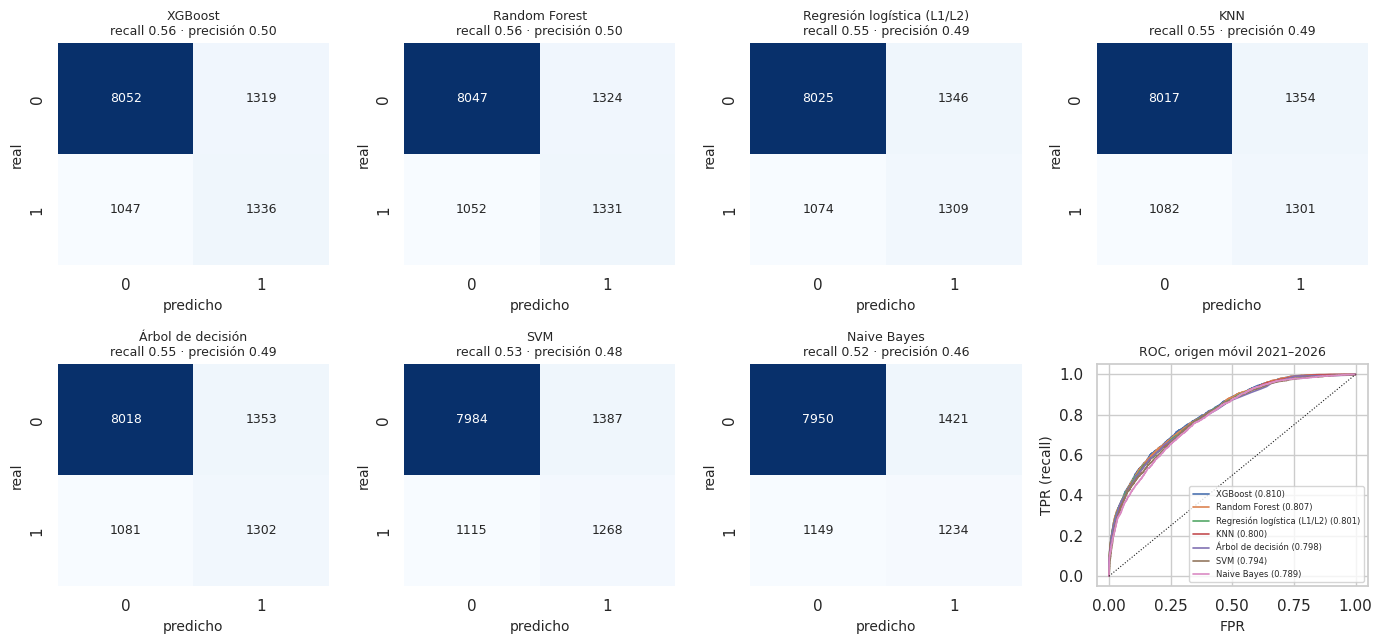

In [7]:
# Matrices de confusión de los campeones
fig, axs = plt.subplots(2, 4, figsize=(14, 6.6))
for ax, (_, f) in zip(axs.flat, TB.iterrows()):
    cm = confusion_matrix(yb, pred_prevalencia(C["combos"][f.etiqueta]))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 9})
    ax.set_title(f"{f.modelo}\nrecall {f.Recall:.2f} · precisión {f.Precision:.2f}", fontsize=9)
    ax.set_xlabel("predicho"); ax.set_ylabel("real")
ax = axs.flat[-1]
for _, f in TB.iterrows():
    fpr, tpr, _ = roc_curve(yb, C["combos"][f.etiqueta])
    ax.plot(fpr, tpr, lw=1.2, label=f"{f.modelo} ({f.AUC:.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=0.8); ax.set_xlabel("FPR"); ax.set_ylabel("TPR (recall)"); ax.set_title("ROC, origen móvil 2021–2026", fontsize=9)
ax.legend(fontsize=6)
plt.tight_layout(); eda.guardar_figura(fig, "e2_clf_cm_roc.png"); plt.show()

Las curvas ROC de los siete modelos están muy juntas en la zona de FPR baja–media, que es la útil para
priorizar, salvo las de los modelos más débiles. Las matrices muestran el compromiso de marcar la proporción
histórica de celdas activas: se aceptan algunas falsas alarmas para no perder celdas activas, de acuerdo con
el costo asimétrico de 17.1.

## 17.4 Comparación de las técnicas de balanceo

Para cada modelo y técnica: AUC (ordenamiento) y recall y F1 con umbral 0,5 (efecto directo del balanceo sobre
la decisión). KNN y Naive Bayes no tienen columna class_weight porque es equivalente a «sin balanceo»
(cap. 13.6).

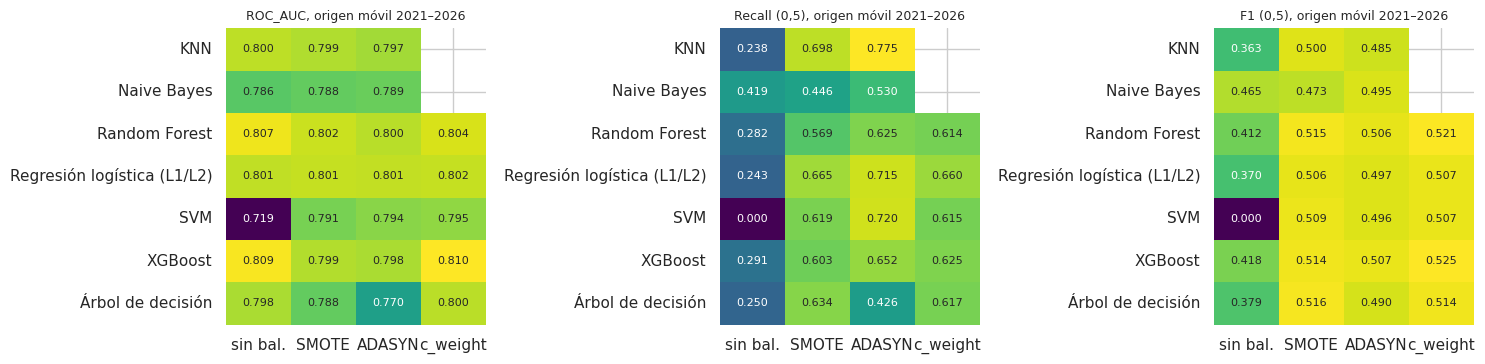

In [8]:
# Efecto de las técnicas de balanceo por modelo (mapas de calor)
orden_b = ["sin bal.", "SMOTE", "ADASYN", "c_weight"]
tabs = {k: TP.pivot(index="modelo", columns="balanceo", values=k)[orden_b] for k in ("ROC_AUC", "Recall (0,5)", "F1 (0,5)")}
eda.guardar_tabla(TP[["modelo", "balanceo", "ROC_AUC", "Recall (0,5)", "F1 (0,5)"]], "e2_clf_balanceo.csv")
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, k in zip(axs, ("ROC_AUC", "Recall (0,5)", "F1 (0,5)")):
    sns.heatmap(tabs[k], annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar=False, annot_kws={"size": 8})
    ax.set_title(f"{k}, origen móvil 2021–2026", fontsize=9); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); eda.guardar_figura(fig, "e2_clf_balanceo.png"); plt.show()

In [9]:
# Lectura del efecto del balanceo
dif = tabs["ROC_AUC"][["SMOTE", "ADASYN", "c_weight"]].sub(tabs["ROC_AUC"]["sin bal."], axis=0)
rec = tabs["Recall (0,5)"][["SMOTE", "ADASYN", "c_weight"]].sub(tabs["Recall (0,5)"]["sin bal."], axis=0)
sin_svm = dif.drop(index="SVM")
fuertes = dif.loc[["XGBoost", "Random Forest", "KNN", "Regresión logística (L1/L2)"]]
md(f"- **AUC (ordenamiento).** Frente a «sin balanceo», el cambio medio en los siete modelos es {dif['SMOTE'].mean():+.3f} con SMOTE, "
   f"{dif['ADASYN'].mean():+.3f} con ADASYN y {np.nanmean(dif['c_weight']):+.3f} con class_weight, pero ese promedio lo arrastra **la SVM**: "
   f"sin balanceo, la SVM ajustada sobre una submuestra de 4 000 filas casi nunca predice la clase positiva y su AUC cae a "
   f"{tabs['ROC_AUC'].loc['SVM', 'sin bal.']:.3f}; con balanceo sube a ≈ {tabs['ROC_AUC'].loc['SVM', ['SMOTE', 'ADASYN', 'c_weight']].mean():.3f}. "
   f"Sin la SVM, los cambios medios son {sin_svm['SMOTE'].mean():+.3f}, {sin_svm['ADASYN'].mean():+.3f} y {np.nanmean(sin_svm['c_weight']):+.3f}, y "
   f"en los cuatro modelos más fuertes (XGBoost, Random Forest, KNN y logística) quedan entre {np.nanmin(fuertes.values):+.3f} y "
   f"{np.nanmax(fuertes.values):+.3f}: el balanceo **apenas cambia la capacidad de ordenar** de los buenos modelos. SMOTE y ADASYN "
   f"interpolan entre vecinos de la clase minoritaria, lo que en un panel con muchas variables de conteo (0, 1, 2 sismos) crea "
   f"combinaciones poco realistas; class_weight solo reescala la pérdida.\n"
   f"- **Recall con umbral 0,5.** Sube en promedio {rec['SMOTE'].mean():+.2f} con SMOTE, {rec['ADASYN'].mean():+.2f} con ADASYN y "
   f"{np.nanmean(rec['c_weight']):+.2f} con class_weight, porque desplazan las probabilidades hacia la clase minoritaria.\n"
   f"- **Conclusión.** El balanceo es imprescindible para la SVM con submuestra y casi neutro para los demás en AUC. Su efecto útil (más "
   f"recall) se consigue igual con una **regla de umbral** sobre el modelo sin balanceo (17.2), sin distorsionar las probabilidades (17.5).")

- **AUC (ordenamiento).** Frente a «sin balanceo», el cambio medio en los siete modelos es +0.007 con SMOTE, +0.004 con ADASYN y +0.015 con class_weight, pero ese promedio lo arrastra **la SVM**: sin balanceo, la SVM ajustada sobre una submuestra de 4 000 filas casi nunca predice la clase positiva y su AUC cae a 0.719; con balanceo sube a ≈ 0.793. Sin la SVM, los cambios medios son -0.004, -0.008 y +0.000, y en los cuatro modelos más fuertes (XGBoost, Random Forest, KNN y logística) quedan entre -0.011 y +0.001: el balanceo **apenas cambia la capacidad de ordenar** de los buenos modelos. SMOTE y ADASYN interpolan entre vecinos de la clase minoritaria, lo que en un panel con muchas variables de conteo (0, 1, 2 sismos) crea combinaciones poco realistas; class_weight solo reescala la pérdida.
- **Recall con umbral 0,5.** Sube en promedio +0.36 con SMOTE, +0.39 con ADASYN y +0.41 con class_weight, porque desplazan las probabilidades hacia la clase minoritaria.
- **Conclusión.** El balanceo es imprescindible para la SVM con submuestra y casi neutro para los demás en AUC. Su efecto útil (más recall) se consigue igual con una **regla de umbral** sobre el modelo sin balanceo (17.2), sin distorsionar las probabilidades (17.5).

## 17.5 Calibración de probabilidades

Para el campeón de cada modelo se evalúa si la probabilidad predicha coincide con la frecuencia observada:
**diagrama de confiabilidad** (10 bins), **Brier** y **ECE**. Se recalibra con **Platt** (regresión logística
sobre el puntaje) y con **regresión isotónica** de forma **secuencial**: para pronosticar el año *Y* (2022 a
2026) la recalibración se ajusta con los pronósticos y resultados de los años anteriores del origen móvil
(2021 a *Y* − 1), que ya eran conocidos. Así nunca se usa información del año evaluado. Las tres versiones se
comparan en 2022–2026 (2021 no tiene años previos para recalibrar). SVM no produce probabilidades: su fila
«sin calibrar» queda vacía.

In [10]:
# Calibración: Brier y ECE sin calibrar, con Platt e isotónica (recalibrando con años previos)
filas, curvas = [], {}
m22 = anio >= 2022
for _, c in CAMP.iterrows():
    s = C["combos"][c.etiqueta]
    pl_, is_ = np.full(len(s), np.nan), np.full(len(s), np.nan)
    for Y in range(2022, 2027):
        a_, b_ = anio < Y, anio == Y
        pl_[b_] = LogisticRegression(C=1e6).fit(s[a_].reshape(-1, 1), yb[a_]).predict_proba(s[b_].reshape(-1, 1))[:, 1]
        is_[b_] = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s[a_], yb[a_]).predict(s[b_])
    versiones = {"sin calibrar": s if es_prob(c.etiqueta) else None, "Platt": pl_, "isotónica": is_}
    for v, p in versiones.items():
        if p is None:
            filas.append({"modelo": c.modelo, "balanceo": c.variante, "versión": v, "Brier": np.nan, "ECE": np.nan,
                          "AUC": roc_auc_score(yb[m22], s[m22])}); continue
        filas.append({"modelo": c.modelo, "balanceo": c.variante, "versión": v, "Brier": brier_score_loss(yb[m22], np.clip(p[m22], 0, 1)),
                      "ECE": est.ece(yb[m22], p[m22]), "AUC": roc_auc_score(yb[m22], p[m22])})
        curvas[(c.modelo, v)] = est.curva_confiabilidad(yb[m22], p[m22])
CAL = pd.DataFrame(filas)
eda.guardar_tabla(CAL, "e2_clf_calibracion.csv")
CAL.pivot(index="modelo", columns="versión", values=["Brier", "ECE"]).round(4)

Brier                            ECE                       
versión                       Platt isotónica sin calibrar   Platt isotónica sin calibrar
modelo                                                                                   
KNN                          0.1259    0.1250       0.1254  0.0327    0.0081       0.0164
Naive Bayes                  0.1380    0.1290       0.1884  0.0197    0.0122       0.1679
Random Forest                0.1240    0.1230       0.1226  0.0364    0.0099       0.0112
Regresión logística (L1/L2)  0.1250    0.1247       0.1255  0.0238    0.0126       0.0262
SVM                          0.1296    0.1295          NaN  0.0212    0.0190          NaN
XGBoost                      0.1231    0.1226       0.1675  0.0189    0.0110       0.1984
Árbol de decisión            0.1258    0.1246       0.1244  0.0320    0.0087       0.0143

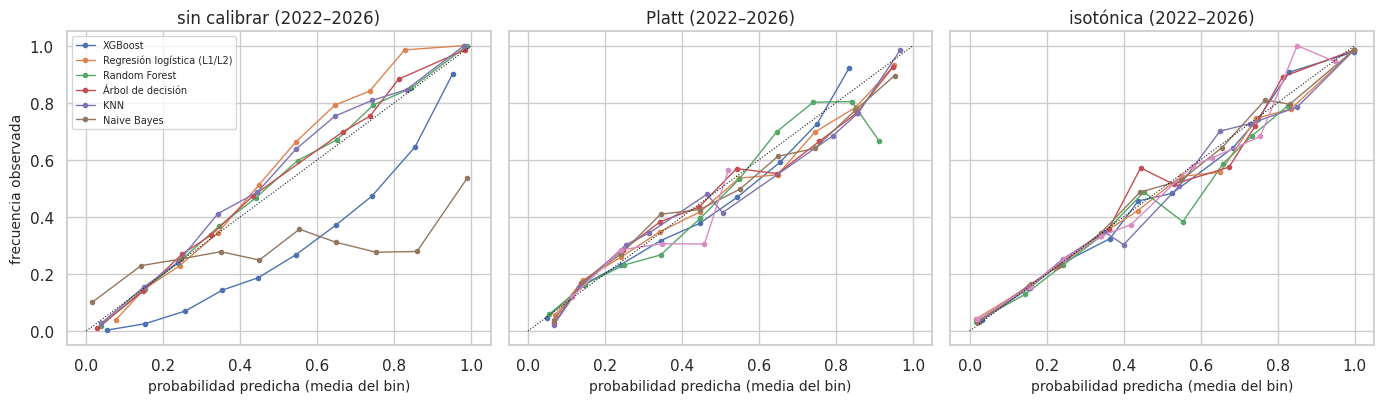

In [11]:
# Diagramas de confiabilidad
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, v in zip(axs, ("sin calibrar", "Platt", "isotónica")):
    for mod in CAMP.modelo:
        if (mod, v) in curvas:
            cv = curvas[(mod, v)]
            ax.plot(cv.p_media, cv.frecuencia, marker="o", ms=3, lw=1, label=mod)
    ax.plot([0, 1], [0, 1], "k:", lw=0.8); ax.set_title(f"{v} (2022–2026)"); ax.set_xlabel("probabilidad predicha (media del bin)")
axs[0].set_ylabel("frecuencia observada"); axs[0].legend(fontsize=7)
plt.tight_layout(); eda.guardar_figura(fig, "e2_clf_confiabilidad.png"); plt.show()

In [12]:
# Lectura de la calibración
sc = CAL[CAL["versión"] == "sin calibrar"].dropna().set_index("modelo")
pl = CAL[CAL["versión"] == "Platt"].set_index("modelo"); iso_ = CAL[CAL["versión"] == "isotónica"].set_index("modelo")
bal_de = dict(zip(CAMP.modelo, CAMP.variante))
malos = sc[sc.ECE > 0.05].index.tolist(); buenos = sc[sc.ECE <= 0.05].index.tolist()
md(f"- **Sin calibrar.** Bien calibrados (ECE ≤ 0,05): {', '.join(f'{m} ({bal_de[m]}, ECE {sc.ECE[m]:.3f})' for m in buenos) or 'ninguno'}. "
   f"Mal calibrados: {', '.join(f'{m} ({bal_de[m]}, ECE {sc.ECE[m]:.3f})' for m in malos) or 'ninguno'}. Los que se entrenaron con balanceo "
   f"cambian la prevalencia que ve el modelo (de ≈ 22 % hacia 50 %), así que sus probabilidades quedan infladas aunque el orden (AUC) sea bueno.\n"
   + (f"- **Recalibrar corrige ese sesgo.** En los mal calibrados el ECE baja de {sc.loc[malos].ECE.mean():.3f} a "
      f"{pl.loc[malos].ECE.mean():.3f} con Platt y a {iso_.loc[malos].ECE.mean():.3f} con isotónica, y el Brier de "
      f"{sc.loc[malos].Brier.mean():.4f} a {pl.loc[malos].Brier.mean():.4f} y {iso_.loc[malos].Brier.mean():.4f}.\n" if malos else "")
   + (f"- **En los ya calibrados** el ECE pasa de {sc.loc[buenos].ECE.mean():.3f} a {pl.loc[buenos].ECE.mean():.3f} (Platt) y "
      f"{iso_.loc[buenos].ECE.mean():.3f} (isotónica).\n" if buenos else "")
   + f"- La SVM, que no da probabilidades, queda con ECE {pl.loc['SVM'].ECE:.3f} (Platt) y {iso_.loc['SVM'].ECE:.3f} (isotónica). Platt casi no "
   f"cambia el AUC (es una transformación monótona); la isotónica puede crear empates por tramos y moverlo un poco.")

- **Sin calibrar.** Bien calibrados (ECE ≤ 0,05): Regresión logística (L1/L2) (sin balanceo, ECE 0.026), Random Forest (sin balanceo, ECE 0.011), Árbol de decisión (sin balanceo, ECE 0.014), KNN (sin balanceo, ECE 0.016). Mal calibrados: XGBoost (class_weight, ECE 0.198), Naive Bayes (ADASYN, ECE 0.168). Los que se entrenaron con balanceo cambian la prevalencia que ve el modelo (de ≈ 22 % hacia 50 %), así que sus probabilidades quedan infladas aunque el orden (AUC) sea bueno.
- **Recalibrar corrige ese sesgo.** En los mal calibrados el ECE baja de 0.183 a 0.019 con Platt y a 0.012 con isotónica, y el Brier de 0.1779 a 0.1306 y 0.1258.
- **En los ya calibrados** el ECE pasa de 0.017 a 0.031 (Platt) y 0.010 (isotónica).
- La SVM, que no da probabilidades, queda con ECE 0.021 (Platt) y 0.019 (isotónica). Platt casi no cambia el AUC (es una transformación monótona); la isotónica puede crear empates por tramos y moverlo un poco.

## 17.6 Conclusiones del capítulo

- Las 26 combinaciones ordenan las celdas con AUC parecidos; la validación anterior a 2016 anticipa
  razonablemente cuáles serán mejores en 2021–2026.
- El balanceo sube el recall con umbral 0,5 y es imprescindible para la SVM con submuestra, pero apenas
  cambia el AUC de los modelos fuertes; una regla de umbral logra el mismo recall sin balancear.
- Las probabilidades de los modelos entrenados con balanceo (y la SVM) requieren recalibración; Platt e
  isotónica, ajustadas solo con años anteriores, la proporcionan.